# 05 — DESI Monte Carlo confidence bands for $w(z)$

This notebook propagates observational uncertainty from the six DESI DR2 radial BAO measurements through a fixed exponential distance model and the paper's reconstruction equation. It is a controlled uncertainty experiment, not another symbolic-regression search.

## 1. Scope and interpretation

The Monte Carlo pipeline is

$$\mathbf{d}^{(k)} \sim \mathcal{N}(\boldsymbol{\mu},\,\mathbf{C}),$$

followed by a refit of

$$D_H(z)/r_d = A\exp(Bz)$$

for every realization. The fitted curve and a sampled sound horizon are then propagated through Eq. (3) of the paper.

Two mock-data centers are kept separate:

- `observed_data`: centered on the six measured DESI values.
- `paper_expression`: centered on $28.4\exp(-0.519z)$.

> These are pointwise Monte Carlo intervals conditional on the exponential model family. They do not include PySR model-selection uncertainty and must not be combined with the seed spread from Notebook 04 as if they were the same uncertainty.

In [1]:
from pathlib import Path
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize_scalar

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Inputs and experiment directory

Every experiment is stored under its own ID. Change `EXPERIMENT_ID` before a genuinely new run so earlier outputs are not overwritten.

In [2]:
RECONSTRUCTION_EXPERIMENT_ID = "seed_ensemble_public_omegam0p30_rd101_20260908"
EXPERIMENT_ID = "fixed_exponential_20000mc_20260909"


def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the required upstream results."""
    for candidate in (start, *start.parents):
        data_file = candidate / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
        reconstruction_dir = (
            candidate / "results" / "04_desi_wz_reconstruction"
            / RECONSTRUCTION_EXPERIMENT_ID
        )
        if data_file.is_file() and reconstruction_dir.is_dir():
            return candidate
    raise FileNotFoundError("Could not locate Notebook 01 and Notebook 04 results.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_FILE = PROJECT_ROOT / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
RECONSTRUCTION_DIR = (
    PROJECT_ROOT / "results" / "04_desi_wz_reconstruction"
    / RECONSTRUCTION_EXPERIMENT_ID
)
REPRESENTATIVE_FILE = RECONSTRUCTION_DIR / "tables" / "representative_exponential_solutions.csv"
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / "results" / "05_desi_monte_carlo_confidence"
RESULTS_DIR = NOTEBOOK_RESULTS_DIR / EXPERIMENT_ID
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
for directory in (NOTEBOOK_RESULTS_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Experiment: {EXPERIMENT_ID}")
print(f"Output directory: {RESULTS_DIR}")

Project root: /Users/kemingliu/Desktop/Dark Energy
Experiment: fixed_exponential_20000mc_20260909
Output directory: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909


## 3. Load the DESI data and covariance alternatives

`public_full` uses the covariance released with the DESI data. `paper_table` is the diagonal covariance reconstructed from the rounded uncertainties printed in Table I of the paper. They remain separate because they are not numerically identical.

In [3]:
with np.load(DATA_FILE) as data:
    z_data = data["z"].astype(float)
    y_data = data["y"].astype(float)
    public_covariance = data["covariance"].astype(float)
    public_sigma = data["sigma"].astype(float)
    tracers = data["tracers"].astype(str)

PAPER_TABLE_SIGMA = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])
paper_table_covariance = np.diag(PAPER_TABLE_SIGMA**2)
COVARIANCE_CONFIGS = {
    "public_full": public_covariance,
    "paper_table": paper_table_covariance,
}
representative_solutions = pd.read_csv(REPRESENTATIVE_FILE)

data_summary = pd.DataFrame({
    "tracer": tracers, "z": z_data, "DH_over_rd": y_data,
    "sigma_public": public_sigma, "sigma_paper_table": PAPER_TABLE_SIGMA,
})
display(data_summary)

,tracer,z,DH_over_rd,sigma_public,sigma_paper_table
0,LRG1,0.510,21.862947,0.428868,0.425
1,LRG2,0.706,19.455349,0.333870,0.330
2,LRG3+ELG1,0.934,17.641495,0.201043,0.193
3,ELG2,1.321,14.176022,0.224551,0.221
4,QSO,1.484,12.817000,0.518012,0.516
5,Ly-alpha,2.330,8.631546,0.101062,0.101


## 4. Exponential fit and physical reconstruction

For a fixed slope $B$, the best amplitude $A$ can be solved analytically using the full inverse covariance. Therefore each Monte Carlo fit only requires a one-dimensional minimization over $B$. This is equivalent to minimizing

$$\chi^2=(\mathbf{m}-\mathbf{d})^T\mathbf{C}^{-1}(\mathbf{m}-\mathbf{d})$$

inside the chosen exponential family.

In [4]:
PAPER_A, PAPER_B = 28.4, -0.519
OMEGA_M = 0.30
RD_MEAN_HINV_MPC = 101.0
RD_SIGMA_HINV_MPC = 2.3
C_KM_S = 299_792.458
Z_GRID = np.linspace(0.0, 2.5, 501)


def exponential_distance(redshift, amplitude, slope):
    """Evaluate A exp(B z)."""
    return amplitude * np.exp(slope * np.asarray(redshift, dtype=float))


def fit_exponential_profile(observed, covariance):
    """Fit A exp(B z) by profiling out A and minimizing chi-square over B."""
    inverse_covariance = np.linalg.inv(covariance)
    observed = np.asarray(observed, dtype=float)

    def profiled_chi2(slope):
        basis = np.exp(slope * z_data)
        amplitude = (basis @ inverse_covariance @ observed) / (basis @ inverse_covariance @ basis)
        residual = amplitude * basis - observed
        return float(residual @ inverse_covariance @ residual)

    result = minimize_scalar(
        profiled_chi2, bounds=(-2.0, 0.0), method="bounded",
        options={"xatol": 1e-11, "maxiter": 200},
    )
    slope = float(result.x)
    basis = np.exp(slope * z_data)
    amplitude = float((basis @ inverse_covariance @ observed) / (basis @ inverse_covariance @ basis))
    return amplitude, slope, float(result.fun), bool(result.success)


def reconstruct_ensemble(amplitudes, slopes, rd_values, redshift=Z_GRID):
    """Vectorize Eq. (3) over fitted parameters and sound-horizon draws."""
    amplitudes = np.asarray(amplitudes)[:, None]
    slopes = np.asarray(slopes)[:, None]
    rd_values = np.asarray(rd_values)[:, None]
    redshift = np.asarray(redshift)[None, :]
    distance = amplitudes * np.exp(slopes * redshift)
    derivative = slopes * distance
    gamma = OMEGA_M * (100.0 * rd_values / C_KM_S) ** 2
    matter_term = gamma * (1.0 + redshift) ** 3 * distance**3
    denominator = 3.0 * (distance - matter_term)
    numerator = 2.0 * (1.0 + redshift) * derivative + 3.0 * matter_term
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        equation_of_state = -1.0 - numerator / denominator
    finite = np.isfinite(equation_of_state)
    equation_of_state[~finite] = np.nan
    pole_factor = 1.0 - gamma * (1.0 + redshift) ** 3 * distance**2
    has_pole = (np.nanmin(pole_factor, axis=1) <= 0.0) & (np.nanmax(pole_factor, axis=1) >= 0.0)
    return distance, equation_of_state, has_pole


def reconstruct_single(amplitude, slope, rd_value=RD_MEAN_HINV_MPC):
    distance, equation_of_state, _ = reconstruct_ensemble([amplitude], [slope], [rd_value])
    return distance[0], equation_of_state[0]

## 5. Deterministic reference fits

These fits must reproduce the deterministic exponential baselines from Notebook 04 before the Monte Carlo experiment is trusted.

In [5]:
baseline_rows = []
baseline_parameters = {}
for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    amplitude, slope, chi2, success = fit_exponential_profile(y_data, covariance)
    baseline_parameters[covariance_name] = (amplitude, slope)
    baseline_rows.append({
        "covariance": covariance_name, "A": amplitude, "B": slope,
        "chi2": chi2, "loss": chi2 / len(z_data), "success": success,
    })
baseline_summary = pd.DataFrame(baseline_rows)
display(baseline_summary)

assert np.isclose(baseline_parameters["public_full"][0], 28.120222, atol=1e-5)
assert np.isclose(baseline_parameters["public_full"][1], -0.508294, atol=1e-5)

,covariance,A,B,chi2,loss,success
0,public_full,28.120223,-0.508294,2.444247,0.407375,True
1,paper_table,28.129755,-0.508460,2.529349,0.421558,True


## 6. Monte Carlo configuration

Twenty thousand realizations provide about 27 samples in each extreme 0.135% tail used for a nominal pointwise $3\sigma$ interval. The $3\sigma$ boundary is therefore more Monte Carlo-sensitive than the $1\sigma$ and $2\sigma$ boundaries.

In [6]:
N_REALIZATIONS = 20_000
RANDOM_SEED = 20250909
CENTER_MODES = ("observed_data", "paper_expression")
QUANTILES = np.array([0.1349898, 2.2750132, 15.8655254, 50.0, 84.1344746, 97.7249868, 99.8650102])
QUANTILE_LABELS = ("q0p135", "q2p275", "q15p866", "median", "q84p134", "q97p725", "q99p865")

paper_mean = exponential_distance(z_data, PAPER_A, PAPER_B)
MOCK_CENTERS = {"observed_data": y_data, "paper_expression": paper_mean}
print(f"Realizations per covariance and center: {N_REALIZATIONS:,}")
print(f"Total exponential fits: {N_REALIZATIONS * len(COVARIANCE_CONFIGS) * len(CENTER_MODES):,}")

Realizations per covariance and center: 20,000
Total exponential fits: 80,000


## 7. Run the Monte Carlo experiment

Each configuration receives an independent reproducible random-number stream. The sound horizon is sampled independently as $r_d\sim\mathcal{N}(101,2.3)$ in $h^{-1}\,\mathrm{Mpc}$, while $\Omega_m=0.30$ is held fixed.

In [7]:
start_time = time.perf_counter()
seed_sequences = np.random.SeedSequence(RANDOM_SEED).spawn(
    len(COVARIANCE_CONFIGS) * len(CENTER_MODES)
)
mc_results = {}
fit_records = []
sequence_index = 0

for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    for center_mode in CENTER_MODES:
        rng = np.random.default_rng(seed_sequences[sequence_index])
        sequence_index += 1
        mock_data = rng.multivariate_normal(MOCK_CENTERS[center_mode], covariance, size=N_REALIZATIONS)
        rd_draws = rng.normal(RD_MEAN_HINV_MPC, RD_SIGMA_HINV_MPC, size=N_REALIZATIONS)
        amplitudes = np.empty(N_REALIZATIONS)
        slopes = np.empty(N_REALIZATIONS)
        chi2_values = np.empty(N_REALIZATIONS)
        successes = np.empty(N_REALIZATIONS, dtype=bool)

        for index, mock_observation in enumerate(mock_data):
            amplitudes[index], slopes[index], chi2_values[index], successes[index] = (
                fit_exponential_profile(mock_observation, covariance)
            )

        valid = successes & np.isfinite(amplitudes) & np.isfinite(slopes) & (amplitudes > 0.0) & (rd_draws > 0.0)
        distance, equation_of_state, has_pole = reconstruct_ensemble(
            amplitudes[valid], slopes[valid], rd_draws[valid]
        )
        key = (covariance_name, center_mode)
        mc_results[key] = {
            "amplitudes": amplitudes[valid], "slopes": slopes[valid],
            "rd": rd_draws[valid], "chi2": chi2_values[valid],
            "distance": distance, "w": equation_of_state, "has_pole": has_pole,
        }
        for valid_index, original_index in enumerate(np.flatnonzero(valid)):
            fit_records.append({
                "covariance": covariance_name, "center_mode": center_mode,
                "realization": int(original_index), "A": amplitudes[original_index],
                "B": slopes[original_index], "rd_hinv_mpc": rd_draws[original_index],
                "chi2": chi2_values[original_index],
                "pole_in_0_to_2p5": bool(has_pole[valid_index])
            })
        print(f"Completed {covariance_name} / {center_mode}: {valid.sum():,} valid fits")

elapsed_seconds = time.perf_counter() - start_time
print(f"Monte Carlo runtime: {elapsed_seconds:.1f} s")

Completed public_full / observed_data: 20,000 valid fits
Completed public_full / paper_expression: 20,000 valid fits
Completed paper_table / observed_data: 20,000 valid fits
Completed paper_table / paper_expression: 20,000 valid fits
Monte Carlo runtime: 7.2 s


## 8. Parameter and pole diagnostics

A pole means that the denominator of Eq. (3) crosses zero somewhere in $0\leq z\leq2.5$. Such realizations are reported rather than silently discarded because they expose instability in derivative-based reconstruction.

In [8]:
summary_rows = []
for (covariance_name, center_mode), result in mc_results.items():
    summary_rows.append({
        "covariance": covariance_name, "center_mode": center_mode,
        "valid_fits": len(result["amplitudes"]),
        "A_median": np.median(result["amplitudes"]),
        "A_std": np.std(result["amplitudes"], ddof=1),
        "B_median": np.median(result["slopes"]),
        "B_std": np.std(result["slopes"], ddof=1),
        "rd_median": np.median(result["rd"]),
        "pole_fraction_0_to_2p5": np.mean(result["has_pole"]),
    })
mc_summary = pd.DataFrame(summary_rows)
display(mc_summary)

,covariance,center_mode,valid_fits,A_median,A_std,B_median,B_std,rd_median,pole_fraction_0_to_2p5
0,public_full,observed_data,20000,28.121904,0.392485,-0.508275,0.009380,100.970978,0.1540
1,public_full,paper_expression,20000,28.404446,0.396237,-0.519007,0.009394,101.015398,0.0695
2,paper_table,observed_data,20000,28.133253,0.382570,-0.508575,0.009205,100.960246,0.1557
3,paper_table,paper_expression,20000,28.400417,0.389905,-0.519052,0.009340,100.974675,0.0692


## 9. Construct pointwise $1\sigma$, $2\sigma$, and $3\sigma$ bands

Quantiles are calculated separately at every redshift. Therefore these are pointwise intervals, not simultaneous confidence regions for the entire curve.

In [9]:
band_records = []
band_arrays = {}
for key, result in mc_results.items():
    distance_quantiles = np.nanpercentile(result["distance"], QUANTILES, axis=0)
    w_quantiles = np.nanpercentile(result["w"], QUANTILES, axis=0)
    band_arrays[key] = {"distance": distance_quantiles, "w": w_quantiles}
    covariance_name, center_mode = key
    for grid_index, redshift in enumerate(Z_GRID):
        row = {"covariance": covariance_name, "center_mode": center_mode, "z": redshift}
        for quantile_index, label in enumerate(QUANTILE_LABELS):
            row[f"distance_{label}"] = distance_quantiles[quantile_index, grid_index]
            row[f"w_{label}"] = w_quantiles[quantile_index, grid_index]
        band_records.append(row)
bands_table = pd.DataFrame(band_records)
display(bands_table.head())

,covariance,center_mode,z,distance_q0p135,w_q0p135,distance_q2p275,w_q2p275,distance_q15p866,w_q15p866,distance_median,w_median,distance_q84p134,w_q84p134,distance_q97p725,w_q97p725,distance_q99p865,w_q99p865
0,public_full,observed_data,0.000,26.943261,-0.957576,27.341339,-0.938254,27.725863,-0.920852,28.121904,-0.904566,28.511463,-0.889566,28.908719,-0.875192,29.346514,-0.860883
1,public_full,observed_data,0.005,26.877785,-0.959374,27.274046,-0.939750,27.656593,-0.922084,28.050762,-0.905551,28.438024,-0.890333,28.832918,-0.875768,29.266862,-0.861281
2,public_full,observed_data,0.010,26.812467,-0.961198,27.207089,-0.941255,27.587839,-0.923334,27.979617,-0.906558,28.364546,-0.891107,28.757454,-0.876371,29.188088,-0.861687
3,public_full,observed_data,0.015,26.747309,-0.963048,27.140523,-0.942820,27.519049,-0.924613,27.908680,-0.907588,28.291457,-0.891903,28.681740,-0.876963,29.110162,-0.862101
4,public_full,observed_data,0.020,26.682309,-0.964925,27.073320,-0.944407,27.450388,-0.925904,27.837617,-0.908617,28.218509,-0.892713,28.606144,-0.877564,29.032444,-0.862523


## 10. Plot the Monte Carlo reconstruction

The nested shading shows $3\sigma$, $2\sigma$, and $1\sigma$ intervals from lightest to darkest. Separate rows prevent the observed-data and paper-centered experiments from being mistaken for one combined result.

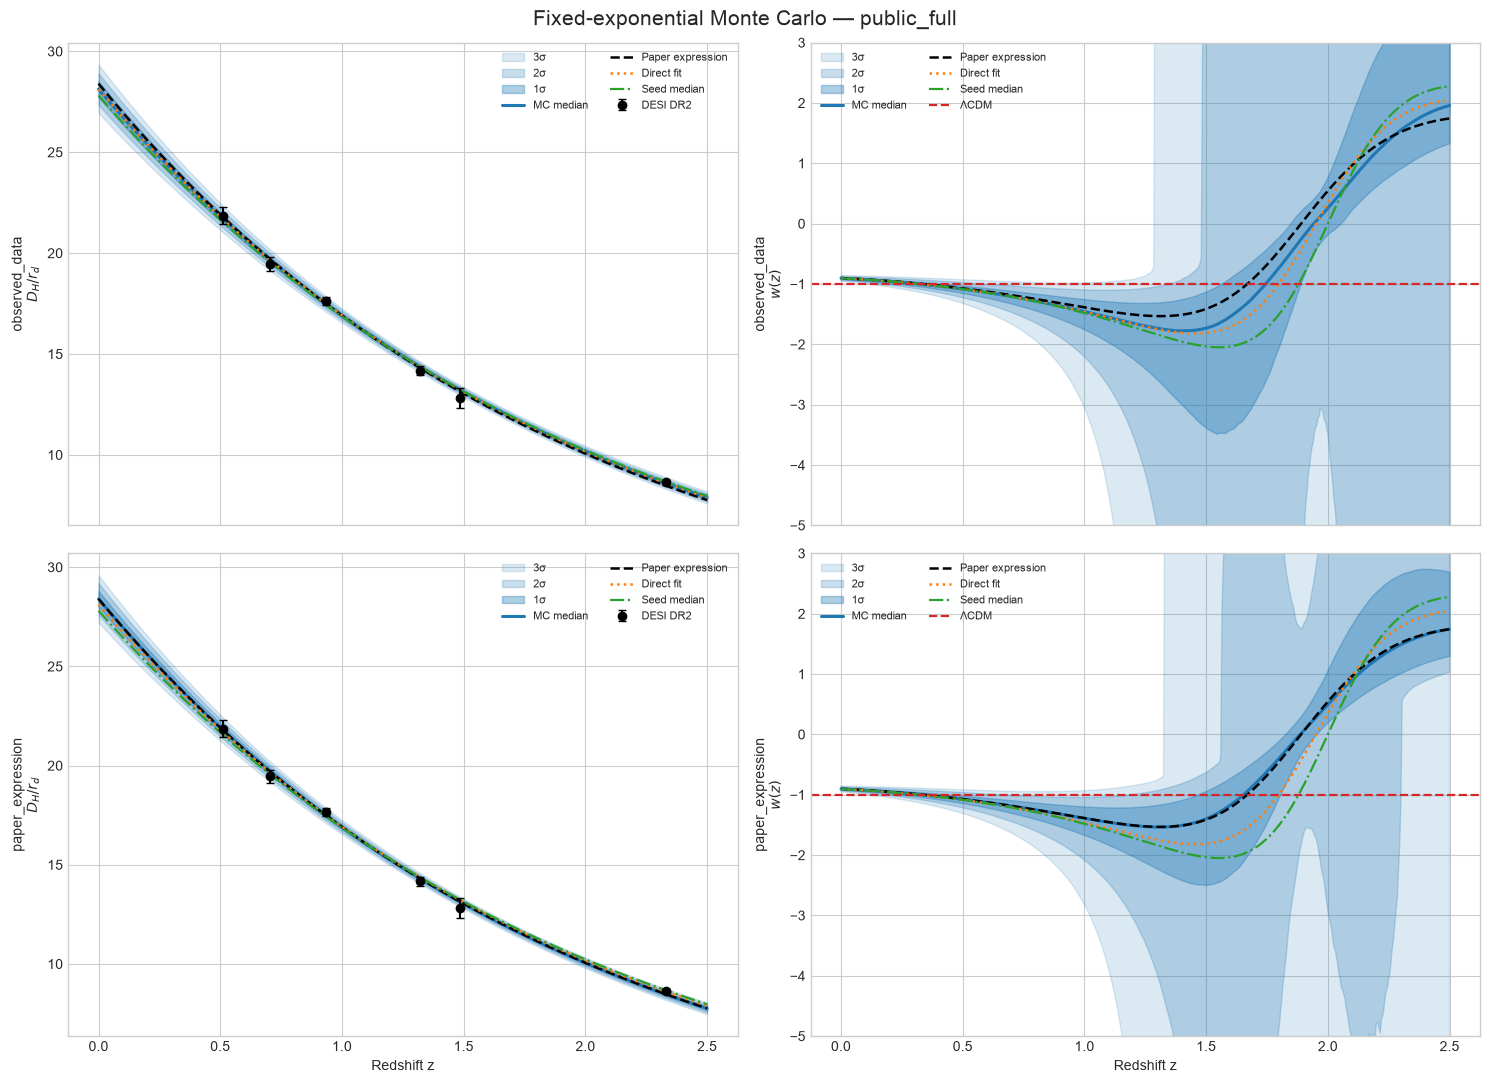

Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/figures/public_full_monte_carlo_bands.png


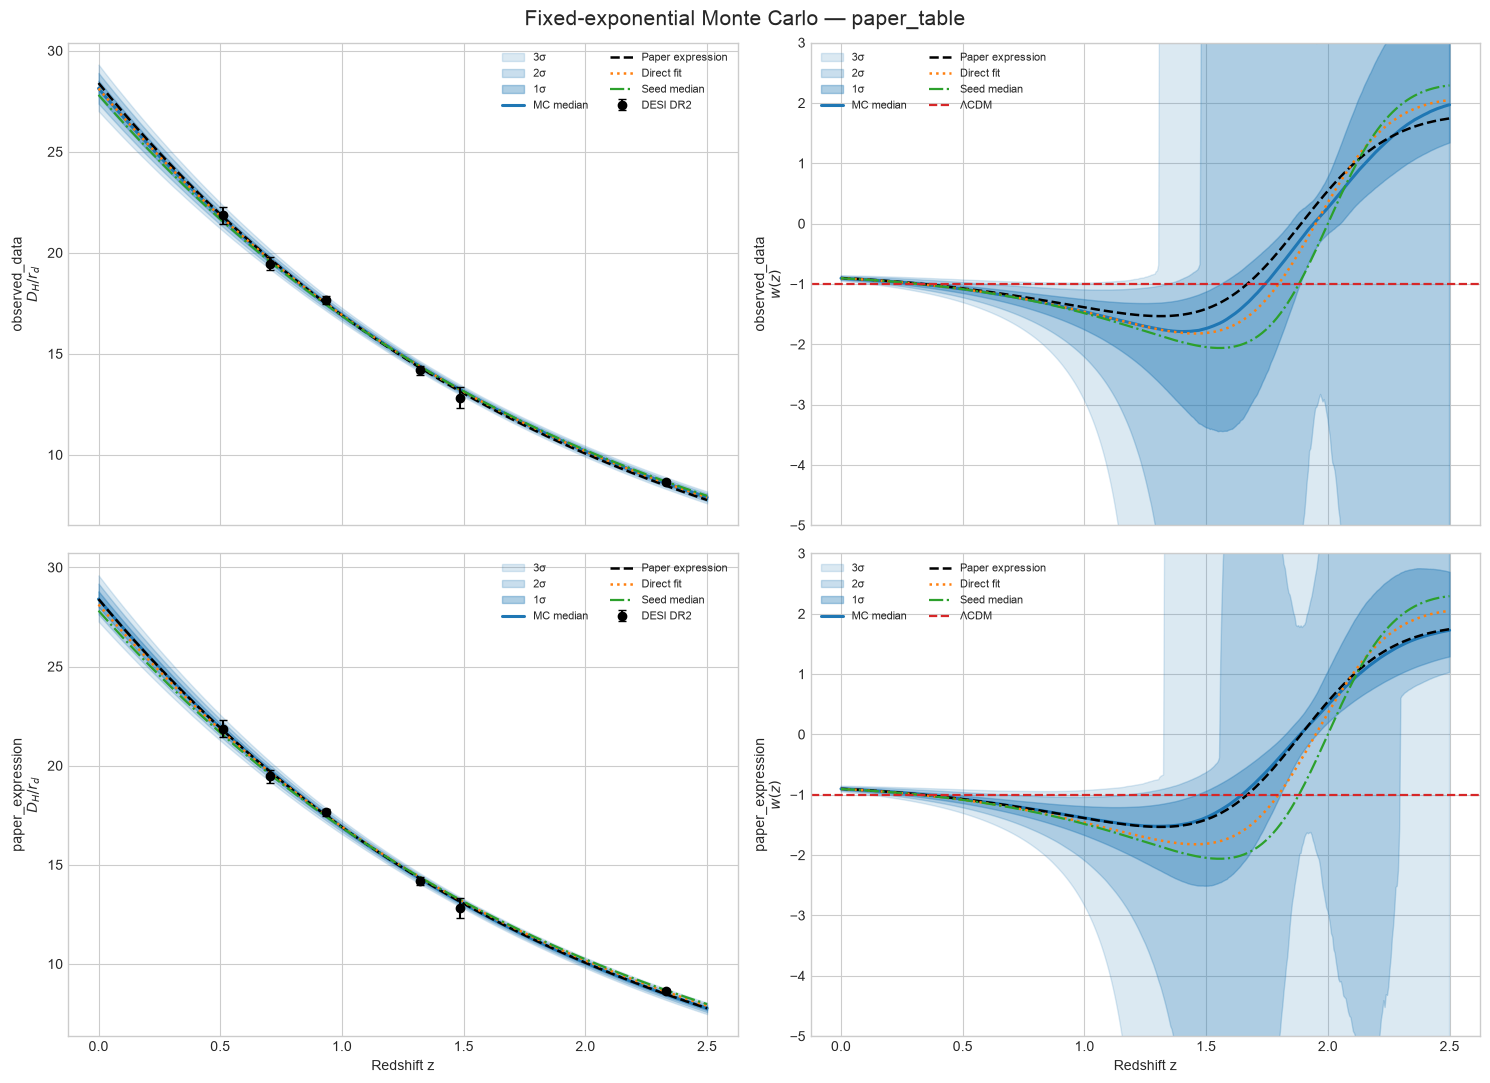

Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/figures/paper_table_monte_carlo_bands.png


In [10]:
paper_distance, paper_w = reconstruct_single(PAPER_A, PAPER_B)
seed_median_parameters = {}
for covariance_name in COVARIANCE_CONFIGS:
    row = representative_solutions.query(
        "covariance == @covariance_name and selection == 'median_representative'"
    ).iloc[0]
    seed_median_parameters[covariance_name] = (float(row["A"]), float(row["B"]))
figure_paths = []
for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    direct_distance, direct_w = reconstruct_single(*baseline_parameters[covariance_name])
    seed_distance, seed_w = reconstruct_single(*seed_median_parameters[covariance_name])
    figure, axes = plt.subplots(2, 2, figsize=(15, 11), sharex="col")
    for row_index, center_mode in enumerate(CENTER_MODES):
        distance_q = band_arrays[(covariance_name, center_mode)]["distance"]
        w_q = band_arrays[(covariance_name, center_mode)]["w"]
        distance_axis, w_axis = axes[row_index]
        for low, high, alpha, label in ((0, 6, 0.16, "3σ"), (1, 5, 0.24, "2σ"), (2, 4, 0.36, "1σ")):
            distance_axis.fill_between(Z_GRID, distance_q[low], distance_q[high], color="tab:blue", alpha=alpha, label=label)
            w_axis.fill_between(Z_GRID, w_q[low], w_q[high], color="tab:blue", alpha=alpha, label=label)
        distance_axis.plot(Z_GRID, distance_q[3], color="tab:blue", lw=2.2, label="MC median")
        distance_axis.plot(Z_GRID, paper_distance, "k--", lw=1.8, label="Paper expression")
        distance_axis.plot(Z_GRID, direct_distance, color="tab:orange", ls=":", lw=1.8, label="Direct fit")
        distance_axis.plot(Z_GRID, seed_distance, color="tab:green", ls="-.", lw=1.6, label="Seed median")
        distance_axis.errorbar(z_data, y_data, yerr=np.sqrt(np.diag(covariance)), fmt="o", color="black", capsize=3, label="DESI DR2")
        w_axis.plot(Z_GRID, w_q[3], color="tab:blue", lw=2.2, label="MC median")
        w_axis.plot(Z_GRID, paper_w, "k--", lw=1.8, label="Paper expression")
        w_axis.plot(Z_GRID, direct_w, color="tab:orange", ls=":", lw=1.8, label="Direct fit")
        w_axis.plot(Z_GRID, seed_w, color="tab:green", ls="-.", lw=1.6, label="Seed median")
        w_axis.axhline(-1.0, color="tab:red", ls="--", lw=1.6, label="ΛCDM")
        distance_axis.set_ylabel(f"{center_mode}\n$D_H/r_d$")
        w_axis.set_ylabel(f"{center_mode}\n$w(z)$")
        w_axis.set_ylim(-5.0, 3.0)
        distance_axis.legend(loc="best", fontsize=8, ncol=2)
        w_axis.legend(loc="best", fontsize=8, ncol=2)
    axes[-1, 0].set_xlabel("Redshift z")
    axes[-1, 1].set_xlabel("Redshift z")
    figure.suptitle(f"Fixed-exponential Monte Carlo — {covariance_name}", fontsize=15)
    figure.tight_layout()
    figure_path = FIGURES_DIR / f"{covariance_name}_monte_carlo_bands.png"
    figure.savefig(figure_path, dpi=180, bbox_inches="tight")
    figure_paths.append(figure_path)
    plt.show()
    print(f"Saved: {figure_path}")

## 11. Selected-redshift evaluation

The Boolean columns test whether $w=-1$ lies inside each pointwise interval. A failure at one redshift is not automatically a global $N\sigma$ rejection of $\Lambda$CDM because the redshift points are correlated and the intervals are not simultaneous.

In [11]:
SELECTED_REDSHIFTS = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5])
diagnostic_rows = []
for key, arrays in band_arrays.items():
    covariance_name, center_mode = key
    for redshift in SELECTED_REDSHIFTS:
        grid_index = int(np.argmin(np.abs(Z_GRID - redshift)))
        q = arrays["w"][:, grid_index]
        diagnostic_rows.append({
            "covariance": covariance_name, "center_mode": center_mode,
            "z": Z_GRID[grid_index], "w_median": q[3],
            "w_1sigma_low": q[2], "w_1sigma_high": q[4],
            "w_2sigma_low": q[1], "w_2sigma_high": q[5],
            "w_3sigma_low": q[0], "w_3sigma_high": q[6],
            "lcdm_in_1sigma": bool(q[2] <= -1.0 <= q[4]),
            "lcdm_in_2sigma": bool(q[1] <= -1.0 <= q[5]),
            "lcdm_in_3sigma": bool(q[0] <= -1.0 <= q[6]),
        })
diagnostic_table = pd.DataFrame(diagnostic_rows)
display(diagnostic_table)

,covariance,center_mode,z,w_median,w_1sigma_low,w_1sigma_high,w_2sigma_low,w_2sigma_high,w_3sigma_low,w_3sigma_high,lcdm_in_1sigma,lcdm_in_2sigma,lcdm_in_3sigma
0,public_full,observed_data,0.0,-0.904566,-0.920852,-0.889566,-0.938254,-0.875192,-0.957576,-0.860883,False,False,False
1,public_full,observed_data,0.5,-1.083473,-1.150067,-1.026930,-1.227932,-0.976599,-1.322344,-0.929786,False,True,True
2,public_full,observed_data,1.0,-1.455966,-1.753201,-1.251755,-2.209305,-1.098783,-3.055208,-0.979863,False,False,True
3,public_full,observed_data,1.5,-1.732036,-3.385834,-1.124347,-12.387720,4.943426,-156.450593,155.797624,False,True,True
4,public_full,observed_data,2.0,0.254709,-0.174383,0.781761,-3.483626,3.995485,-64.161883,67.914595,False,True,True
5,public_full,observed_data,2.5,1.957955,1.336632,3.652998,-5.202965,12.973163,-187.048107,253.814410,False,True,True
6,public_full,paper_expression,0.0,-0.901894,-0.918281,-0.886372,-0.935721,-0.871454,-0.955166,-0.857070,False,False,False
7,public_full,paper_expression,0.5,-1.073470,-1.139724,-1.015779,-1.216813,-0.964130,-1.311523,-0.917723,False,True,True
8,public_full,paper_expression,1.0,-1.390864,-1.668506,-1.194401,-2.084686,-1.044751,-2.822763,-0.933101,False,False,True
9,public_full,paper_expression,1.5,-1.398612,-2.492592,-0.936653,-7.492389,-0.629885,-92.036423,65.366121,True,True,True


## 12. Save reproducible outputs

The configuration file records the exact assumptions needed to distinguish this experiment from later alternatives.

In [12]:
FIT_SAMPLES_FILE = TABLES_DIR / "monte_carlo_fit_samples.csv.gz"
SUMMARY_FILE = TABLES_DIR / "monte_carlo_summary.csv"
BANDS_FILE = TABLES_DIR / "monte_carlo_bands.csv"
DIAGNOSTIC_FILE = TABLES_DIR / "selected_redshift_diagnostics.csv"
BASELINE_FILE = TABLES_DIR / "deterministic_baselines.csv"
ARRAY_FILE = RESULTS_DIR / "monte_carlo_bands.npz"
CONFIGURATION_FILE = RESULTS_DIR / "configuration.json"

fit_samples = pd.DataFrame(fit_records)
fit_samples.to_csv(FIT_SAMPLES_FILE, index=False, compression="gzip")
mc_summary.to_csv(SUMMARY_FILE, index=False)
bands_table.to_csv(BANDS_FILE, index=False)
diagnostic_table.to_csv(DIAGNOSTIC_FILE, index=False)
baseline_summary.to_csv(BASELINE_FILE, index=False)

array_payload = {"z": Z_GRID, "quantiles_percent": QUANTILES}
for (covariance_name, center_mode), arrays in band_arrays.items():
    prefix = f"{covariance_name}__{center_mode}"
    array_payload[f"{prefix}__distance"] = arrays["distance"]
    array_payload[f"{prefix}__w"] = arrays["w"]
np.savez_compressed(ARRAY_FILE, **array_payload)

configuration = {
    "experiment_id": EXPERIMENT_ID,
    "source_reconstruction_experiment": RECONSTRUCTION_EXPERIMENT_ID,
    "n_realizations_per_configuration": N_REALIZATIONS,
    "random_seed": RANDOM_SEED,
    "center_modes": list(CENTER_MODES),
    "covariance_configurations": list(COVARIANCE_CONFIGS),
    "model_family": "A * exp(B z)",
    "slope_search_bounds": [-2.0, 0.0],
    "paper_expression": {"A": PAPER_A, "B": PAPER_B},
    "cosmology": {
        "omega_m_fixed": OMEGA_M, "rd_mean_hinv_mpc": RD_MEAN_HINV_MPC,
        "rd_sigma_hinv_mpc": RD_SIGMA_HINV_MPC, "c_km_s": C_KM_S,
    },
    "pointwise_quantiles_percent": QUANTILES.tolist(),
    "runtime_seconds": elapsed_seconds,
    "uncertainty_interpretation": (
        "Observational Monte Carlo uncertainty conditional on a fixed exponential model family; "
        "does not include PySR structural/model-selection uncertainty."
    ),
    "software_versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
    },
}
with CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(configuration, stream, indent=2)

for path in (FIT_SAMPLES_FILE, SUMMARY_FILE, BANDS_FILE, DIAGNOSTIC_FILE,
             BASELINE_FILE, ARRAY_FILE, CONFIGURATION_FILE, *figure_paths):
    print(f"Saved: {path}")

Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/tables/monte_carlo_fit_samples.csv.gz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/tables/monte_carlo_summary.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/tables/monte_carlo_bands.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/tables/selected_redshift_diagnostics.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/tables/deterministic_baselines.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponential_20000mc_20260909/monte_carlo_bands.npz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/05_desi_monte_carlo_confidence/fixed_exponen

## 13. Evaluation checklist

Use the saved results to answer the following questions before changing the symbolic-regression settings:

- Do the deterministic fits reproduce Notebook 04?
- How strongly do the intervals change between `public_full` and `paper_table`?
- How strongly do they change when the simulations are centered on the observed data versus the paper expression?
- Does the denominator of Eq. (3) cross zero for a substantial fraction of realizations?
- Is $w=-1$ outside a pointwise interval, and if so, at which redshifts and confidence level?
- Can the paper's plotted band be reproduced without undocumented assumptions?

A mismatch should first be recorded as a reproducibility diagnostic. Do not tune Notebook 03 or 04 merely to force agreement.